# Online-Order Pressure → U.S. Courier Employment

**An executed, falsifiable retrospective macro-factor pilot**  
**Research date:** 2026-10-27 | **PIT status:** NOT PIT | **Equity alpha:** NOT TESTED

This notebook is an independent, computational research record with original data checks, formal forecasting rules, OOS scorecards, falsification and limitations. It uses a frozen 2026-revised source snapshot, not a historical vintage panel. **Do not use this as a trading signal.**

### Reading guide and evidentiary boundary

The original K-Food reference notebook has 36 cells and combines economic mechanism, issuer exposures, point-in-time logic, company fundamentals, return tests and falsification. Here the target is a **national payroll series**, so company fundamental tests and stock return IC/spreads are explicitly not applicable. The notebook computes charts and tables from frozen input; visual output does not repair source-vintage leakage.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, SVG
from analysis import prepare, walkforward, score, gain, ridge, rank_ic, fast_factor_predictions
R=Path.cwd(); assert (R/'study.json').exists()
REGENERATED_AT_START=not (R/'results/block_permutation_1000.csv').is_file()
if REGENERATED_AT_START:
    subprocess.run([sys.executable,'run_analysis.py'],cwd=R,stdout=subprocess.DEVNULL,stderr=subprocess.STDOUT,check=True)
print('Study:',R.name,'| input file:',(R/'data/frozen_quarterly_courier_ecommerce_2026-10-26.csv').name)

Study: Online-Order-Pressure-to-Courier-Employment-U.S.-Parcel-Delivery | input file: frozen_quarterly_courier_ecommerce_2026-10-26.csv


## 01. Abstract

**Question.** Does lagged e-commerce demand pressure anticipate two-quarter-ahead U.S. couriers-and-messengers employment growth, after accounting for courier persistence and broad payroll conditions? This is a **retrospective, revised-data macro lead-factor falsification**, not an investable equity study. The 61 purged expanding-window origins show RMSE 4.629 log-pp for the augmented model versus 5.148 for macro controls and 4.639 for simple persistence. The gain is concentrated in 2020–2021; bootstrap uncertainty spans zero. **Verdict: FAIL as a stable incremental predictor; no PIT or equity-alpha claim.**

In [2]:
meta=json.loads((R/'study.json').read_text());print({k:meta[k] for k in ['id','industry','outcome','research_status','equity_alpha_established']})

{'id': 'online-order-pressure-us-courier-messengers-2026-10-27', 'industry': 'U.S. couriers and messengers (NAICS 492), not warehousing', 'outcome': 'Two-quarter-ahead U.S. couriers-and-messengers employment YoY log growth', 'research_status': 'REPRODUCED MACRO PILOT — revised snapshot, NOT PIT; regime unstable', 'equity_alpha_established': False}


In [3]:
summary=json.loads((R/'results/summary.json').read_text());print('Saved OOS origins:',summary['oos_origins'],'| PIT:',summary['pit_status'])

Saved OOS origins: 61 | PIT: NOT PIT: fixed revised snapshot with assumed one-quarter release buffer


## 02. Research Design & Hypotheses

**Primary hypothesis H1:** a one-quarter-stale online retail-share acceleration relative to warehousing payroll capacity predicts higher courier hiring two quarters later. **H2:** the fixed signal improves expanding-window OOS RMSE against courier persistence and courier+macro controls, not merely in-sample fit. **H3:** any improvement persists before 2020, after 2021 and under alternate lag/horizon definitions. Null: no incremental forecast improvement over controls. Counterthesis: platform insourcing, automation, route density, union contracts and non-retail deliveries decouple retail-share growth from aggregate courier payrolls. Predeclared failure gate: lose to the strongest simple baseline or a nonpositive gain outside the pandemic regime.

In [4]:
hypotheses={'H1':'Demand minus capacity pressure leads courier hiring','H2':'Positive incremental OOS improvement versus strong baselines','H3':'Robustness across pre-2020/post-2021, lags and horizons'}
display(pd.DataFrame({'hypothesis':list(hypotheses),'test':list(hypotheses.values())}))

,hypothesis,test
0,H1,Demand minus capacity pressure leads courier h...
1,H2,Positive incremental OOS improvement versus st...
2,H3,"Robustness across pre-2020/post-2021, lags and..."


In [5]:
print('Null: zero incremental forecasting value. Counterthesis: automation, insourcing and route density dominate labor demand.')

Null: zero incremental forecasting value. Counterthesis: automation, insourcing and route density dominate labor demand.


## 03. Industry Context

The outcome covers **NAICS 492 couriers and messengers**, not NAICS 493 warehousing and storage, which was the dependent variable in an earlier study. The Census Bureau reported Q2 2026 seasonally adjusted e-commerce at **17.1%** of U.S. retail sales (August 18, 2026; revised-status notice September 28). The BLS CES series measures payroll employees in thousands, not parcel volumes, market share, physical capacity or carrier profits. Delivery networks mix consumer parcels, business shipments and non-retail demand, so e-commerce retail share is only a noisy exposure proxy. UPS and FedEx filings document delivery business lines, but historical issuer revenue weights are not measured here.

In [6]:
raw=pd.read_csv(R/'data/frozen_quarterly_courier_ecommerce_2026-10-26.csv');display(raw.iloc[[0,1,-3,-2,-1]])

,observation_date,ECOMPCTSA,CES4349300001,CES4349200001,PAYEMS
0,2000-01-01,0.8,511.4,594.3,131245.0
1,2000-04-01,0.9,515.9,601.0,132017.0
104,2026-01-01,17.0,1831.3,1058.9,158559.0
105,2026-04-01,17.1,1841.6,1091.2,158850.0
106,2026-07-01,NaN,1835.4,1091.3,158980.0


Rows: 107 | Couriers (latest, thousands): 1091.3 | Warehouse (latest, thousands): 1835.4


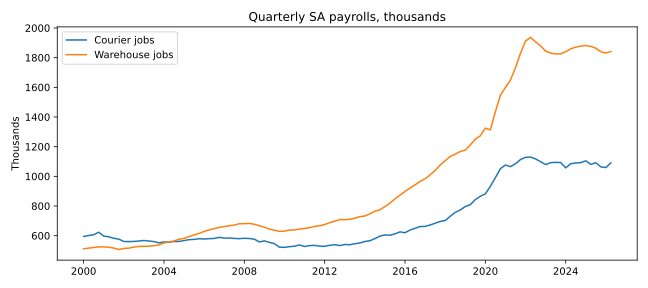

In [7]:
print('Rows:',len(raw),'| Couriers (latest, thousands):',raw['CES4349200001'].iloc[-1],'| Warehouse (latest, thousands):',raw['CES4349300001'].iloc[-1]);display(SVG(filename=str(R/'figures/01_courier_warehouse_levels.svg')))

## 04. Data & Source Integrity

The frozen inherited quarterly snapshot has **107 raw rows (106 complete quarters, 2000Q1–2026Q2; partial 2026Q3 excluded)** and four official series identifiers. The target is CES4349200001; predictors are ECOMPCTSA, CES4349300001 and PAYEMS. `data/source_register.csv` assigns A to original government series/documentation, B to the inherited frozen transport layer and C to researcher modeling assumptions. **Unknown:** historical source-publication timestamps, real-time vintage histories, original monthly-to-quarterly averaging audit and exhaustive source-row corroboration. SHA-256 `17b99d105505b7c4ef7741012cf65d916bac0b907403474f18cffedcc4a99b2d` permits reproducibility of the reused snapshot, not original-source accuracy.

In [8]:
src=pd.read_csv(R/'data/source_register.csv');display(src[['source_id','grade','publisher','latest_document_release_date','historical_vintages']]);print('A/B/C source grades:',src.grade.value_counts().to_dict())

,source_id,grade,publisher,latest_document_release_date,historical_vintages
0,ECOMPCTSA,A,U.S. Census Bureau via FRED,2026-08-18,NOT RETRIEVED
1,CES4349200001,A,U.S. Bureau of Labor Statistics via FRED,2026-10-02,NOT RETRIEVED
2,CES4349300001,A,U.S. Bureau of Labor Statistics via FRED,2026-10-02,NOT RETRIEVED
3,PAYEMS,A,U.S. Bureau of Labor Statistics via FRED,2026-10-02,NOT RETRIEVED
4,CENSUS_RELEASE,A,U.S. Census Bureau,2026-08-18,NOT RETRIEVED
5,UPS_10K,A,UPS investor relations,2026-02-17,NOT RETRIEVED
6,FDX_10K,A,U.S. SEC,2025-07-21,NOT RETRIEVED
7,REUSED_SNAPSHOT,B,Signals-to-Alpha earlier online-retail study,2026-10-26,NOT RETRIEVED
8,HYPOTHESIS,C,Researcher,2026-10-27,NOT APPLICABLE


A/B/C source grades: {'A': 7, 'B': 1, 'C': 1}


In [9]:
print('Missing by series:',raw.isna().sum().to_dict());print('Duplicate quarters:',raw.observation_date.duplicated().sum());print('Frozen SHA256:',hashlib.sha256((R/'data/frozen_quarterly_courier_ecommerce_2026-10-26.csv').read_bytes()).hexdigest())

Missing by series: {'observation_date': 0, 'ECOMPCTSA': 1, 'CES4349300001': 0, 'CES4349200001': 0, 'PAYEMS': 0}
Duplicate quarters: 0
Frozen SHA256: 17b99d105505b7c4ef7741012cf65d916bac0b907403474f18cffedcc4a99b2d


## 05. Point-in-Time Availability

At formation quarter *t*, all signals use observations from *t−1* or earlier. This operational buffer accommodates the typical delay in quarterly Census releases but **does not verify each release date**. Each training origin *j* enters only if its two-quarter-ahead outcome plus one additional quarterly publication buffer is observable by *t*: **j+2+1 ≤ t**. Historical CES revisions, Census methodology changes, and seasonal rebenchmarking remain embedded in the frozen 2026 snapshot. Therefore the model is a **fixed-revised-snapshot counterfactual**, not a true real-time tradable backtest.

In [10]:
d=prepare(raw);display(d[['date','last_signal_observation','target_date','target_known_after','share_yoy_pp','target']].iloc[[5,6,50,80,103]])

,date,last_signal_observation,target_date,target_known_after,share_yoy_pp,target
5,2001-04-01,2001-01-01,2001-10-01,2002-01-01,0.3,-7.706379
6,2001-07-01,2001-04-01,2002-01-01,2002-04-01,0.2,-6.360125
50,2012-07-01,2012-04-01,2013-01-01,2013-04-01,0.5,2.283888
80,2020-01-01,2019-10-01,2020-07-01,2020-10-01,1.3,16.144481
103,2025-10-01,2025-07-01,2026-04-01,NaT,0.2,1.031697


In [11]:
assert (d.last_signal_observation.dropna()<d.formation_date.loc[d.last_signal_observation.notna()]).all()
print('Signals use t-1 or older; training labels are purged through t-3; revision-vintage status remains UNKNOWN.')

Signals use t-1 or older; training labels are purged through t-3; revision-vintage status remains UNKNOWN.


## 06. Factor Construction

For quarter *t*, define `ΔShare[t−1] = ECOMPCTSA[t−1] − ECOMPCTSA[t−5]` (percentage points); `gW[t−1]=100 ln(W[t−1]/W[t−5])` and `gP[t−1]=100 ln(P[t−1]/P[t−5])` (log-pp). The **predefined demand–capacity pressure factor** is `S[t] = ΔShare[t−1] − 0.10 × (gW[t−1] − gP[t−1])`. The 0.10 coefficient is a hypothesis-driven scale convention, **not estimated or calibrated from future observations**. The target is `Y[t]=100 ln(C[t+2]/C[t−2])`, two-quarter-ahead courier employment YoY log growth. Train-only feature centering and scaling precede a fixed-alpha Ridge fit.

In [12]:
display(d[['date','share_yoy_pp','capacity_premium','factor','target']].dropna().head(8));assert np.allclose(d.factor.dropna(),(d.share_yoy_pp-.1*d.capacity_premium).dropna())

,date,share_yoy_pp,capacity_premium,factor,target
5,2001-04-01,0.3,1.276951,0.172305,-7.706379
6,2001-07-01,0.2,0.970677,0.102932,-6.360125
7,2001-10-01,0.1,-0.462936,0.146294,-5.573876
8,2002-01-01,0.2,-2.393567,0.439357,-3.761486
9,2002-04-01,0.2,-0.429007,0.242901,-2.280001
10,2002-07-01,0.3,0.096464,0.290354,1.223745
11,2002-10-01,0.4,2.320572,0.167943,0.729476
12,2003-01-01,0.3,4.503600,-0.150360,-0.160585


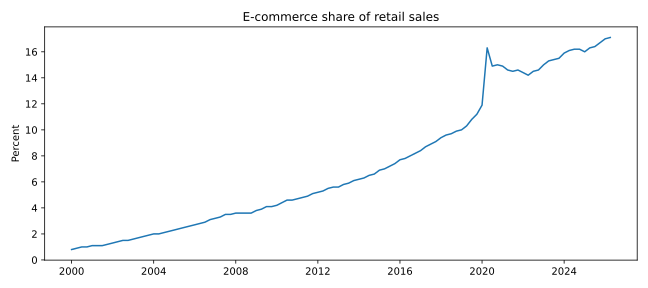

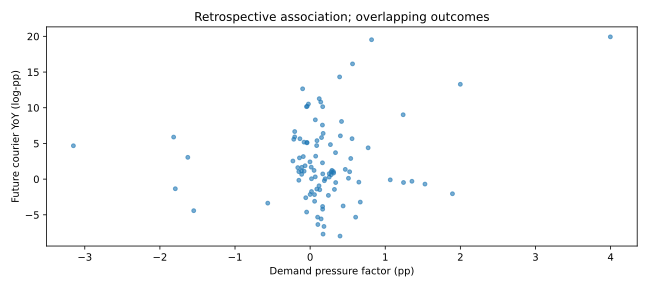

In [13]:
display(SVG(filename=str(R/'figures/02_ecommerce_share.svg')));display(SVG(filename=str(R/'figures/03_factor_target.svg')))

## 07. Exposure & Transmission

The signal-to-outcome chain is retail online-order penetration → distribution demand → courier labor demand, offset by warehouse hiring relative to total payrolls. The NAICS 492 target and NAICS 493 capacity proxy are separately measured; they are not interchangeable. `data/exposure_map.csv` identifies two illustrative listed issuers (UPS, FedEx) with dated filing links, but **no numeric company exposure weights, historical firm fundamentals or returns** are used. Consequently issuer leave-one-out and long–short return spread are **not applicable**; leave-one-calendar-year-out is the feasible aggregate-data sensitivity test.

In [14]:
exposure=pd.read_csv(R/'data/exposure_map.csv');display(exposure[['entity','kind','mapping','as_of','quantified_weight','included_in_panel']]);print('Company fundamentals tested: 0; equity total returns tested: 0.')

,entity,kind,mapping,as_of,quantified_weight,included_in_panel
0,NAICS 492,industry target,Couriers and messengers payroll; not packages ...,2026-10-02,not estimated,yes
1,NAICS 493,upstream capacity,Warehousing and storage payroll; not physical ...,2026-10-02,0.10 fixed coefficient in signal,yes
2,UPS,illustrative issuer,U.S. Domestic Package segment is exposed to pa...,2026-02-17,UNKNOWN,no
3,FedEx,illustrative issuer,Parcel delivery operations; company mix and fi...,2025-07-21,UNKNOWN,no


Company fundamentals tested: 0; equity total returns tested: 0.


## 08. Outcomes & Baselines

The five baselines are historical expanding mean, courier YoY persistence, courier+aggregate-payroll Ridge controls, courier+payroll+warehouse controls, and factor-only Ridge. The challenger adds `S[t]` to courier+payroll controls. All Ridge models use fixed `alpha=10`, standardized using training observations only, and the same 61 valid origins (2010Q4–2025Q4); the train window expands and purges three quarters to avoid unavailable labels. Primary metric: OOS RMSE in log percentage points; secondary MAE, bias and a descriptive **time-series** Spearman coefficient (not cross-sectional equity IC).

In [15]:
o=walkforward(d);assert len(o)==summary['oos_origins'];display(o[['date','target_date','n_train','last_training_target_date','actual','mean','persistence','macro','warehouse_control','factor_only','full']].head())

,date,target_date,n_train,last_training_target_date,actual,mean,persistence,macro,warehouse_control,factor_only,full
0,2010-10-01,2011-04-01,36,2010-07-01,1.360051,-1.466519,-2.308630,-1.699936,-2.121810,-3.931738,-2.768537
1,2011-01-01,2011-07-01,37,2010-10-01,1.053433,-1.348820,-0.136993,-0.822578,-1.775400,-2.382747,-1.655895
2,2011-04-01,2011-10-01,38,2011-01-01,-1.443189,-1.286200,-0.655660,-0.528079,-1.190591,-2.164959,-1.055745
3,2011-07-01,2012-01-01,39,2011-04-01,0.284441,-1.218347,-0.523259,-0.474706,-1.289253,-1.691221,-0.736801
4,2011-10-01,2012-04-01,40,2011-07-01,0.318442,-1.161553,-0.544831,-0.112518,-0.510025,-0.942215,-0.145235


In [16]:
print('OOS origins:',len(o),'range:',o.date.min().date(),o.date.max().date());print('Purge minimum quarters:',min((o.date.dt.to_period('Q')-o.last_training_target_date.dt.to_period('Q')).apply(lambda x:x.n)))

OOS origins: 61 range: 2010-10-01 2025-10-01
Purge minimum quarters: 1


## 09. Empirical Findings

**Observed:** RMSE mean **6.828**, courier persistence **4.639**, macro controls **5.148**, warehouse controls **5.457**, factor-only **8.697**, augmented **4.629** log-pp. Incremental macro-relative RMSE gain is **+0.519** log-pp, but the augmented model improves on courier persistence by only **+0.009** log-pp and has worse MAE than persistence. Time-series Spearman signal/target is **+0.005**. Positive full-sample improvement must not be read as a stable effect.

In [17]:
s=score(o);display(s);print('Macro-relative RMSE gain:',gain(o),'Warehouse-control-relative gain:',gain(o,'warehouse_control'))

,model,n,rmse,mae,bias
0,mean,61,6.828360,5.651725,-3.701240
1,persistence,61,4.638681,3.637262,-1.219487
2,macro,61,5.148432,3.967300,-1.634039
3,warehouse_control,61,5.456955,4.183300,-1.247938
4,factor_only,61,8.696872,6.657354,-4.560959
5,full,61,4.629231,3.914412,-1.338087


Macro-relative RMSE gain: 0.5192010746074471 Warehouse-control-relative gain: 0.8277244148037681


Time-series Spearman (not equity IC): 0.004970914859862506


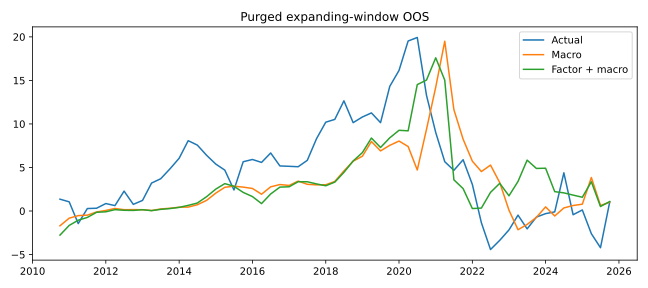

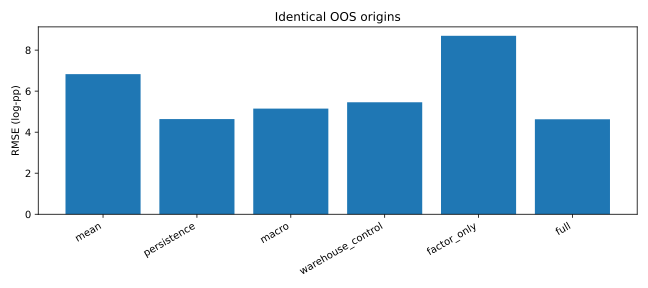

In [18]:
print('Time-series Spearman (not equity IC):',rank_ic(o,d.factor));display(SVG(filename=str(R/'figures/04_oos_predictions.svg')));display(SVG(filename=str(R/'figures/05_model_scorecard.svg')))

In [19]:
residual=o.actual-o.full;print('Full-model residual quartiles:',residual.quantile([0,.25,.5,.75,1]).to_dict());print('Full-model MAE:',abs(residual).mean())

Full-model residual quartiles: {0.0: -9.36330040172651, 0.25: -1.4617843845969878, 0.5: 2.351917732150271, 0.75: 4.403940003216626, 1.0: 10.31889334718247}
Full-model MAE: 3.9144120355876995


## 10. Robustness & Placebos

A 1,000-refit permutation of contiguous four-quarter factor blocks yields an **exploratory** upper-tail fraction **0.0010**; nonexchangeability, overlapping outcomes and secular trends prevent treating this as an exact p-value. A 2,000-draw paired four-quarter circular-block bootstrap gives macro-relative RMSE-gain interval **[-0.390, +1.388]**, which includes zero. Among 1,000 predeclared capacity-weight perturbations (0–0.30), **30.1%** improve macro RMSE. Component ablations, warehouse-control comparison, extra release lags and alternative horizons are saved in results tables.

Exploratory placebo tail: 0.000999000999000999


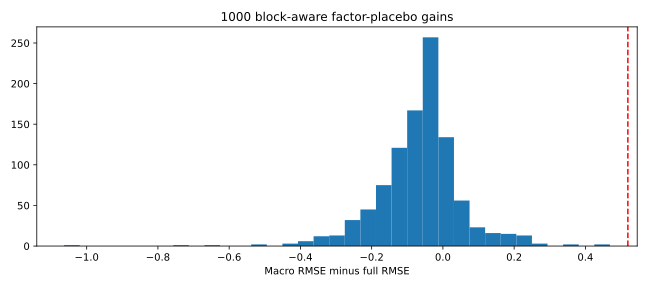

In [20]:
perm=pd.read_csv(R/'results/block_permutation_1000.csv');assert len(perm)==1000
print('Exploratory placebo tail:',(1+(perm.gain_macro>=gain(o)).sum())/(len(perm)+1));display(SVG(filename=str(R/'figures/06_placebo.svg')))

Paired-block gain 95% interval: [-0.38967724  1.38778446]


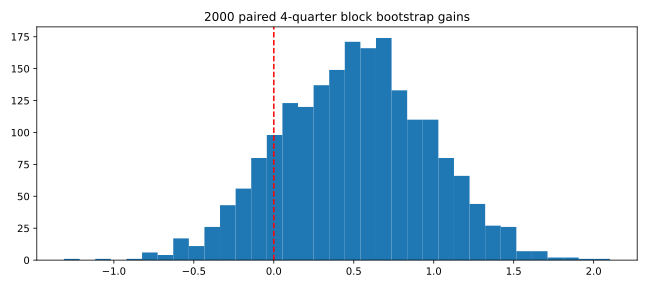

In [21]:
boot=pd.read_csv(R/'results/block_bootstrap_2000.csv');assert len(boot)==2000
print('Paired-block gain 95% interval:',np.quantile(boot.gain_macro,[.025,.975]));display(SVG(filename=str(R/'figures/07_bootstrap.svg')))

Share with positive gain: 0.301


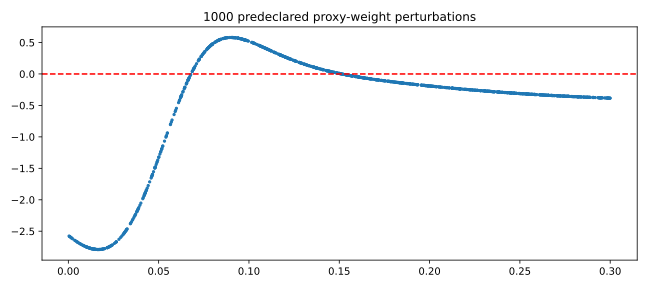

In [22]:
pert=pd.read_csv(R/'results/exposure_perturbation_1000.csv');assert len(pert)==1000
print('Share with positive gain:',(pert.gain_macro>0).mean());display(SVG(filename=str(R/'figures/08_perturbations.svg')))

In [23]:
for fn in ['ablations.csv','lag_sensitivity.csv','horizon_sensitivity.csv']:
 print(fn);display(pd.read_csv(R/'results'/fn))

ablations.csv


,ablation,n,gain_macro,gain_warehouse
0,no_ecommerce,61,-0.423834,-0.115310
1,no_capacity,61,-2.567636,-2.259113


lag_sensitivity.csv


,extra_quarters_stale,n,gain_macro,gain_warehouse
0,0,61,0.519201,0.827724
1,1,60,-0.500114,-0.239328
2,2,59,-1.295615,-1.058481
3,3,58,-1.025346,-0.799274


horizon_sensitivity.csv


,horizon_quarters,n,gain_macro,gain_warehouse
0,1,63,0.579860,0.617150
1,2,61,0.519201,0.827724
2,3,59,0.070494,0.666183
3,4,57,-0.619306,0.015132


## 11. Regime Sensitivity

The pre-2020 sample (37 origins) has macro-relative RMSE gain **-0.037**; the 2020–2021 sample (8) has **+2.863**; the post-2021 sample (16) has **-0.375**. The improvement is therefore pandemic-dominated and reverses sign outside that window. This is a **structural-instability failure**, not evidence of a general-purpose courier hiring factor.

,period,n,gain_macro,gain_warehouse
0,pre_2020,37,-0.037391,0.074929
1,pandemic_2020_2021,8,2.863388,3.538743
2,post_2021,16,-0.375298,0.045141


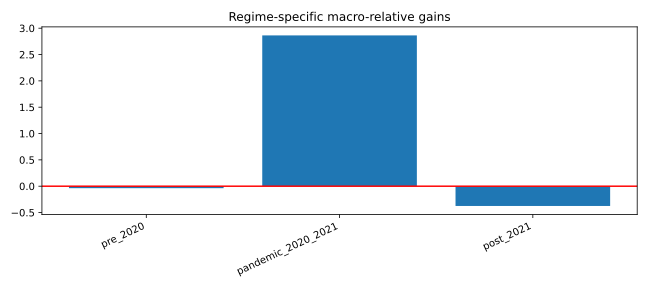

In [24]:
reg=pd.read_csv(R/'results/regimes.csv');display(reg);display(SVG(filename=str(R/'figures/09_regimes.svg')))

In [25]:
loo=pd.read_csv(R/'results/leave_one_year_out.csv');display(loo.sort_values('gain_macro').iloc[[0,1,-2,-1]]);print('Positive leave-year-out share:',(loo.gain_macro>0).mean())

,excluded_year,n,gain_macro,gain_warehouse
10,2020,57,0.070946,0.719482
11,2021,57,0.396331,0.277561
6,2016,57,0.591296,0.939373
13,2023,57,0.756101,1.075897


Positive leave-year-out share: 1.0


## 12. Bias Audit & Verdict

**Lookahead:** historical revised source values are known only ex post; fixed one-quarter buffer cannot reconstruct the first-released values. **Selection:** this industry and factor were selected after earlier adjacent-sector studies; multiple-testing adjustment is unavailable. **Survivorship:** aggregate CES industry classifications can be rebenchmarked; no firm universe was sampled. **Dependence:** two-quarter-ahead YoY targets overlap, reducing effective independent observations. **Costs/capacity:** no securities strategy, portfolio, transaction-cost model or benchmark-adjusted returns exist. **Verdict: negative as a stable macro leading indicator; no investable equity alpha.**

In [26]:
audits={'historical vintages':'NOT RETRIEVED','source revision leakage':'YES, fixed 2026 snapshot','company survivorship':'NOT APPLICABLE to aggregate CES','multiple testing':'NOT CORRECTED','overlapping target':'YES, 4Q YoY targets','equity returns and costs':'NOT TESTED'}
display(pd.DataFrame(audits.items(),columns=['risk','status']))

,risk,status
0,historical vintages,NOT RETRIEVED
1,source revision leakage,"YES, fixed 2026 snapshot"
2,company survivorship,NOT APPLICABLE to aggregate CES
3,multiple testing,NOT CORRECTED
4,overlapping target,"YES, 4Q YoY targets"
5,equity returns and costs,NOT TESTED


In [27]:
print('Verdict: FAIL stable macro-factor gate; pre/post pandemic macro-relative gain is negative; no validated PIT or equity alpha.')

Verdict: FAIL stable macro-factor gate; pre/post pandemic macro-relative gain is negative; no validated PIT or equity alpha.


## 13. Reproduction

From the study directory: `python run_analysis.py`, `PYTHONPATH=. python -m pytest -q tests`, and `jupyter nbconvert --to notebook --execute research.ipynb --output reproduced.ipynb`. Required dependencies are in `requirements.txt`; all random generators have fixed seeds. Generated tables, diagnostic SVGs and `logs/` execution records are versioned. A clean-directory reproduction is required before publication; `scripts/validate_studies.py` is a structural check only.

In [28]:
print('Checking 1000-permutation + 2000-bootstrap analysis from frozen input...')
if REGENERATED_AT_START:
    print('Analysis was regenerated from frozen input at notebook start.')
else:
    proc=subprocess.run([sys.executable,'run_analysis.py'],capture_output=True,text=True,check=True)
    print('Analysis return code:',proc.returncode,'| stdout lines:',len(proc.stdout.splitlines()))
print('Saved result count:',len(list((R/'results').glob('*'))),'| SVG count:',len(list((R/'figures').glob('*.svg'))))


Checking 1000-permutation + 2000-bootstrap analysis from frozen input...
Analysis was regenerated from frozen input at notebook start.
Saved result count: 11 | SVG count: 9


In [29]:
assert json.loads((R/'results/summary.json').read_text())['oos_origins']==len(o)
print('Notebook code executed; numerical results regenerated in study directory.')

Notebook code executed; numerical results regenerated in study directory.


## 14. Next-Stage Protocol

Retrieve actual FRED/ALFRED and Census release vintages, plus month-by-month original BLS observations with their timestamps; rebuild quarterly aggregates from only data available at each decision time. Collect parcel volumes, yield, package mix, labor productivity and delivery-platform insourcing histories; validate issuer segment revenue/operating profit and as-filed 10-K dates. Pre-register a later holdout period, multiple-hypothesis correction, alternative 1–4-quarter horizons, issuer exposure weights, total-return series and transaction-cost assumptions. Abandon the proposed alpha thesis if it cannot beat persistence across non-pandemic regimes and real-time vintages.

In [30]:
protocol=pd.DataFrame([['PIT','ALFRED + Census archival release vintage','Missing'],['Firm outcomes','UPS/FDX filed segment volume and revenue by filing date','Missing'],['Securities','delisted-inclusive total returns + sector benchmark + costs','Missing'],['Holdout','new preregistered non-pandemic period','Missing']],columns=['gate','collection plan','status']);display(protocol)

,gate,collection plan,status
0,PIT,ALFRED + Census archival release vintage,Missing
1,Firm outcomes,UPS/FDX filed segment volume and revenue by fi...,Missing
2,Securities,delisted-inclusive total returns + sector benc...,Missing
3,Holdout,new preregistered non-pandemic period,Missing


## 15. Sources & Artifacts

Primary series and dated releases: [Census e-commerce](https://www.census.gov/retail/ecommerce.html), [FRED ECOMPCTSA](https://fred.stlouisfed.org/series/ECOMPCTSA), [FRED CES4349200001](https://fred.stlouisfed.org/series/CES4349200001), [FRED CES4349300001](https://fred.stlouisfed.org/series/CES4349300001), [FRED PAYEMS](https://fred.stlouisfed.org/series/PAYEMS), [UPS 2025 annual filings](https://investors.ups.com/sec-filings/annual-filings), [FedEx 2025 10-K](https://www.sec.gov/Archives/edgar/data/1048911/000104891125000011/fdx-20250531.htm). Frozen raw/derived CSVs, `analysis.py`, `run_analysis.py`, source register, exposure map, tests, results, figures and execution logs accompany the notebook. These source URLs establish **provenance**, not complete historical PIT validity.

In [31]:
print('Source register rows:',len(src),'| frozen input rows:',len(raw),'| executed OOS origins:',len(o))
print('Artifacts:',', '.join(sorted(p.name for p in (R/'figures').glob('*.svg'))))

Source register rows: 9 | frozen input rows: 107 | executed OOS origins: 61
Artifacts: 01_courier_warehouse_levels.svg, 02_ecommerce_share.svg, 03_factor_target.svg, 04_oos_predictions.svg, 05_model_scorecard.svg, 06_placebo.svg, 07_bootstrap.svg, 08_perturbations.svg, 09_regimes.svg


In [32]:
assert len(list((R/'figures').glob('*.svg')))>=3
assert len(perm)>=1000 and len(boot)>=2000 and len(pert)>=1000
print('Research verdict: retrospective macro falsification, not a point-in-time investable alpha study.')

Research verdict: retrospective macro falsification, not a point-in-time investable alpha study.
